# CloudSentinel-GRCA demo

End-to-end walk-through: synthetic data → fit detector + graph → detect → rank → brief → call the API.

Run from the repo root after `pip install -e ".[dev,notebook]"`.

In [1]:
# Hop up to the repo root if the kernel started in notebooks/.
import os
from pathlib import Path
if Path.cwd().name == 'notebooks':
    os.chdir(Path.cwd().parent)
print('cwd:', Path.cwd())

cwd: /home/claude/project_02_cloudsentinel_grca


## 1. Generate synthetic multi-entity telemetry

In [2]:
from cloudsentinel.data.synthetic import SyntheticConfig, write_sample_dataset
paths = write_sample_dataset('data/sample', SyntheticConfig(
    n_entities=24, n_services=6, duration_days=7, cadence_minutes=5,
    incident_count=12, seed=42))
for name, p in paths.items():
    print(f'{name}: {p}')

telemetry: data/sample/telemetry.csv
entities: data/sample/entities.csv
dependencies: data/sample/dependencies.csv
incidents: data/sample/incidents.csv
cesnet_external: data/sample/cesnet_external.csv


## 2. Inspect the entities and the service dependency graph

In [3]:
import pandas as pd
entities = pd.read_csv('data/sample/entities.csv')
deps = pd.read_csv('data/sample/dependencies.csv')
incidents = pd.read_csv('data/sample/incidents.csv')
print('Entities:', len(entities), '| Services:', entities['service'].nunique())
print('Dependency edges:', len(deps))
print('Labeled incidents:', len(incidents))
display(incidents.head())

Entities: 24 | Services: 6
Dependency edges: 6
Labeled incidents: 12


,incident_id,pattern,root_entity,driving_metric,start_time,end_time,affected_entities
0,inc_000,spike,ent_23,latency_ms,2024-01-07 04:25:00,2024-01-07 06:10:00,"ent_05,ent_11,ent_17,ent_23"
1,inc_001,drift,ent_14,memory_util,2024-01-04 04:25:00,2024-01-04 06:10:00,"ent_02,ent_03,ent_04,ent_05,ent_08,ent_09,ent_..."
2,inc_002,saturation,ent_16,cpu_util,2024-01-02 01:25:00,2024-01-02 02:20:00,"ent_04,ent_10,ent_16,ent_22"
3,inc_003,correlated_failure,ent_22,error_rate,2024-01-04 15:45:00,2024-01-04 17:25:00,"ent_04,ent_10,ent_16,ent_22"
4,inc_004,spike,ent_15,latency_ms,2024-01-05 12:30:00,2024-01-05 13:10:00,"ent_03,ent_09,ent_15,ent_21"


## 3. Train the detector + build the entity graph

In [4]:
from cloudsentinel.train import main as train_main
rc = train_main(['--base-config', 'configs/base.yaml',
                 '--data-config', 'configs/data_ibm.yaml',
                 '--model-config', 'configs/model_grca.yaml'])
print('train rc:', rc)

03:07:43 [INFO] cloudsentinel.train: Training slice: 135552 rows up to 2024-01-05T21:35:00.000000


03:08:09 [INFO] cloudsentinel.train: encoder epoch=0 loss=91.7151


03:08:09 [INFO] cloudsentinel.train: encoder epoch=1 loss=89.0026


03:08:09 [INFO] cloudsentinel.train: encoder epoch=2 loss=77.5583


03:08:09 [INFO] cloudsentinel.train: encoder epoch=3 loss=74.1080


03:08:09 [INFO] cloudsentinel.train: encoder epoch=4 loss=63.2875


03:08:09 [INFO] cloudsentinel.train: Training complete. positive_rate=0.0173 n_series=96


train rc: 0


## 4. Evaluate and inspect detection + RCA metrics

In [5]:
import json
from cloudsentinel.evaluate import main as evaluate_main
evaluate_main(['--base-config', 'configs/base.yaml',
               '--data-config', 'configs/data_ibm.yaml',
               '--model-config', 'configs/model_grca.yaml'])
report = json.load(open('artifacts/eval_report.json'))
print('Detection:')
for k, v in report['point_detection'].items():
    print(f'  {k}: {v}')
print('Best F1 threshold:', report['best_threshold'])
print('RCA:', report['rca'])
print('OOD:', report['ood'])

03:08:19 [INFO] cloudsentinel.evaluate: Eval done. AUROC=0.7962602900595972 AUPRC=0.0788692511483756 top1=1.000 top3=1.000


Detection:
  n: 57984
  positive_rate: 0.01131346578366446
  auroc: 0.7962602900595972
  auprc: 0.0788692511483756
  precision_at_threshold: 0.0
  recall_at_threshold: 0.0
  f1_at_threshold: 0.0
  threshold: 0.7
Best F1 threshold: {'threshold': 0.07307692307692308, 'f1': 0.15558838010832102}
RCA: {'top_1_accuracy': 1.0, 'top_3_accuracy': 1.0, 'top_5_accuracy': 1.0, 'n_incidents': 2}
OOD: {'available': True, 'n_series': 6, 'n_timesteps': 12096, 'mean_prob': 0.037160669795462856, 'p95_prob': 0.1824561403508772, 'max_prob': 0.4864864864864864}


## 5. Plot the detector's three streams for one series

Plotting ent_23 / latency_ms  mean_prob=0.036


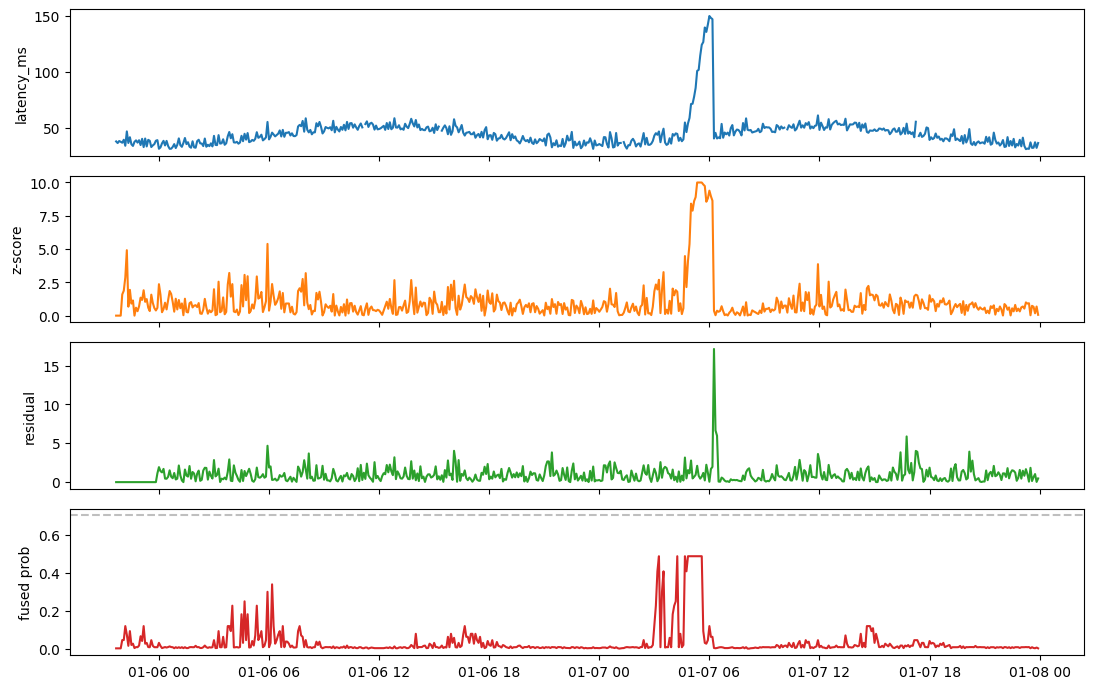

In [6]:
import pandas as pd, matplotlib.pyplot as plt
scored = pd.read_csv('artifacts/scored_events.csv', parse_dates=['timestamp'])
# Pick the series with the highest mean probability.
series_ranking = (
    scored.groupby(['entity_id', 'metric'])['prob'].mean().sort_values(ascending=False)
)
ent, met = series_ranking.index[0]
print(f'Plotting {ent} / {met}  mean_prob={series_ranking.iloc[0]:.3f}')
s = scored[(scored.entity_id == ent) & (scored.metric == met)].sort_values('timestamp')
fig, axes = plt.subplots(4, 1, figsize=(11, 7), sharex=True)
axes[0].plot(s.timestamp, s.value); axes[0].set_ylabel(met)
axes[1].plot(s.timestamp, s.zscore, color='tab:orange'); axes[1].set_ylabel('z-score')
axes[2].plot(s.timestamp, s.residual, color='tab:green'); axes[2].set_ylabel('residual')
axes[3].plot(s.timestamp, s.prob, color='tab:red'); axes[3].set_ylabel('fused prob')
axes[3].axhline(0.7, linestyle='--', color='gray', alpha=0.5)
plt.tight_layout(); plt.show()

## 6. Generate incident briefs

In [7]:
from cloudsentinel.incident_brief import main as brief_main
brief_main(['--base-config', 'configs/base.yaml',
            '--data-config', 'configs/data_ibm.yaml',
            '--model-config', 'configs/model_grca.yaml'])

from pathlib import Path
md_files = sorted(Path('artifacts/briefs').glob('*.md'))
print(f'Wrote {len(md_files)} briefs')
if md_files:
    print('---- first 35 lines of', md_files[0].name, '----')
    print('\n'.join(md_files[0].read_text().splitlines()[:35]))

03:08:21 [INFO] cloudsentinel.incident_brief: Wrote 2 briefs to artifacts/briefs


Wrote 2 briefs
---- first 35 lines of inc_000.md ----
# Incident Brief — inc_000

> **Causality disclaimer.** This brief identifies *candidate driver* entities and *suggestive patterns* based on anomaly signals and graph context. It does not prove root cause. A human operator should review the evidence and run the recommended follow-up checks before taking any action.

## Summary

- **Window:** 2024-01-07 04:25:00 → 2024-01-07 06:10:00
- **Confidence language:** Evidence is weakly suggestive
- **Detector threshold applied:** 0.70
- **Ground-truth incident** (synthetic label): pattern `spike`

## Candidate driver entities (graph RCA)

| Rank | Entity | Service | Score | Seed intensity |
|---:|:---|:---|---:|---:|
| 1 | ent_23 | service_05 | 0.0719 | 0.2872 |
| 2 | ent_17 | service_05 | 0.0465 | 0.0917 |
| 3 | ent_02 | service_02 | 0.0443 | 0.0416 |
| 4 | ent_05 | service_05 | 0.0443 | 0.0767 |
| 5 | ent_08 | service_02 | 0.0430 | 0.0335 |

## Graph evidence paths

- **ent_23** — path: `

## 7. Call the API in-process

In [8]:
from fastapi.testclient import TestClient
from cloudsentinel.serve import create_app
app = create_app('artifacts')
client = TestClient(app)
print('health:', client.get('/health').json())

# Score a real telemetry series (first entity's latency).
telemetry = pd.read_csv('data/sample/telemetry.csv', parse_dates=['timestamp'])
sub = telemetry[(telemetry.entity_id == 'ent_00') & (telemetry.metric == 'latency_ms')].sort_values('timestamp')
values = sub['value'].dropna().tolist()[:200]
score = client.post('/score', json={'entity_id': 'ent_00', 'metric': 'latency_ms', 'values': values}).json()
print('score[prob] first 5:', [round(p, 3) for p in score['prob'][:5]])
print('score[prob] max:', round(max(score['prob']), 3))

03:08:22 [INFO] httpx: HTTP Request: GET http://testserver/health "HTTP/1.1 200 OK"


health: {'status': 'ok', 'n_nodes': 24, 'detector_rolling_window': 48, 'detector_fusion_trained': True, 'model_version': '0.1.0'}


03:08:23 [INFO] httpx: HTTP Request: POST http://testserver/score "HTTP/1.1 200 OK"


score[prob] first 5: [0.004, 0.004, 0.004, 0.006, 0.005]
score[prob] max: 0.486
